In [1]:
# pytorch
import torch
from torch_geometric.utils import degree, homophily
from dataset import CLASS_NAMES, load_facebook_data

# sklearn
from sklearn.model_selection import train_test_split

# plotting
import seaborn as sbn
#import matplotlib.pyplot as plt
from matplotlib import pyplot as plt

## Multi-Layer GNN for Facebook Page Classification
### COMP3710 Working Prototype Project in the Era of Artificial Intelligence
#### Derek McKinney (dm-uq)
#### SN: 45506053

### Data Pipeline
<br>
References:

Facebook Page-Page dataset:
    https://github.com/gayanku/facebook_page-page_dataset

PyG FacebookPagePage:
    https://pytorch-geometric.readthedocs.io/en/latest/generated/torch_geometric.datasets.FacebookPagePage.html

Constants

In [2]:
# NOTE: placeholder cell for definition of constants

#### Data Inspection

In [15]:
# load the FacebookPagePage dataset
dataset = load_facebook_data()

# inspect data properties
print(f'Dataset: {dataset}')
print(f'Number of graphs: {len(dataset)}')
print(f'Number of features: {dataset.num_features}')
print(f'Number of classes: {dataset.num_classes}')

data = dataset[0]  # get first graph object

print('\nGraph data format:')
print(data)

Dataset: FacebookPagePage()
Number of graphs: 1
Number of features: 128
Number of classes: 4

Graph data format:
Data(x=[22470, 128], edge_index=[2, 342004], y=[22470])


Basic EDA

In [16]:
# inspect labels
classes, counts = torch.unique(data.y, return_counts=True)

print('Class counts:')
for cls, count in zip(classes.tolist(), counts.tolist()):
    print(f'  {cls}: {count} ({CLASS_NAMES[cls]})')

label_count = counts.sum().item()
node_count: int = data.num_nodes
print(f'\nNum missing labels: {node_count - label_counts}')

Class counts:
  0: 6495 (tvshow)
  1: 6880 (government)
  2: 5768 (company)
  3: 3327 (politician)

Num missing labels: 0


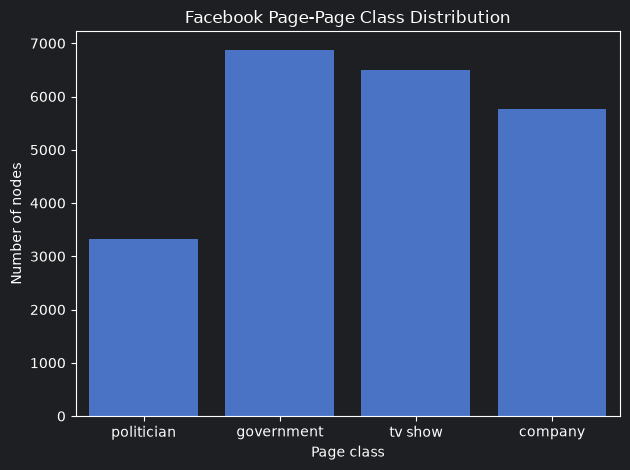

In [60]:
# get class labels for plot
class_labels = [CLASS_NAMES[label] for label in data.y.tolist()]

plt.figure()
ax_class_counts = sbn.countplot(x=class_labels)

plt.xlabel("Page class")
plt.ylabel("Number of nodes")
plt.title("Facebook Page-Page Class Distribution")

plt.tight_layout()
fig_class_counts = ax_class_counts.get_figure()


Degree min:    1
Degree median: 7
Degree mean:   15.22
Degree max:    709


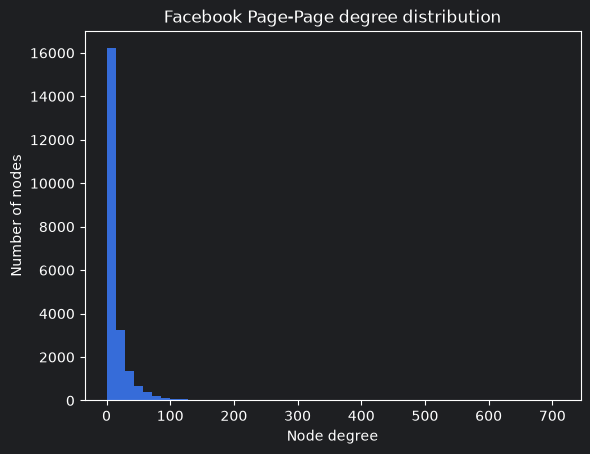

In [43]:
# inspect degrees
deg = degree(
    data.edge_index[0],
    num_nodes=data.num_nodes,
)

print()
print(f"Degree min:    {deg.min().item():.0f}")
print(f"Degree median: {deg.median().item():.0f}")
print(f"Degree mean:   {deg.mean().item():.2f}")
print(f"Degree max:    {deg.max().item():.0f}")

plt.hist(deg.cpu(), bins=50)
plt.xlabel("Node degree")
plt.ylabel("Number of nodes")
plt.title("Facebook Page-Page degree distribution")
plt.show()

In [44]:
# inspect features
print()
print(f"Feature min:   {data.x.min().item():.4f}")
print(f"Feature max:   {data.x.max().item():.4f}")
print(f"Feature mean:  {data.x.mean().item():.4f}")
print(f"Feature std:   {data.x.std().item():.4f}")
print(f"Zero fraction: {(data.x == 0).float().mean().item():.4f}")


Feature min:   -2.0376
Feature max:   3.0020
Feature mean:  0.0103
Feature std:   0.2551
Zero fraction: 0.0000


In [47]:
# inspect graph structure
print()
print(f'Has isolated nodes: {data.has_isolated_nodes()}')
print(f'Has self-loops: {data.has_self_loops()}')
print(f'Is undirected: {data.is_undirected()}')


Has isolated nodes: False
Has self-loops: True
Is undirected: True


In [46]:
# inspect homophily (i.e. how likely nodes with the same label are near each other in a graph)
print()
print(
    f"Edge homophily: "
    f"{homophily(data.edge_index, data.y, method='edge'):.4f}"
)


Edge homophily: 0.8854
